# Pure Pursuit Path Tracking

This notebook implements a Pure Pursuit path-tracking controller using the kinematic bicycle model.

The controller selects a target point ahead of the vehicle on a reference path and calculates a steering command based on the geometric relationship between the vehicle and the target point.

The implementation is evaluated using different lookahead distances to examine their influence on tracking behaviour.

In [1]:
# 1-17D — Environment and Library Setup

import numpy as np
import matplotlib.pyplot as plt

print("Libraries loaded successfully.")

Libraries loaded successfully.


## Reference Path

A curved reference path is created for the vehicle to follow.

A sinusoidal path is used because its continuously changing curvature provides a more meaningful test for path tracking than a simple straight line.

Number of reference points: 600
Path start: (0.00, 0.00)
Path end:   (30.00, 1.41)


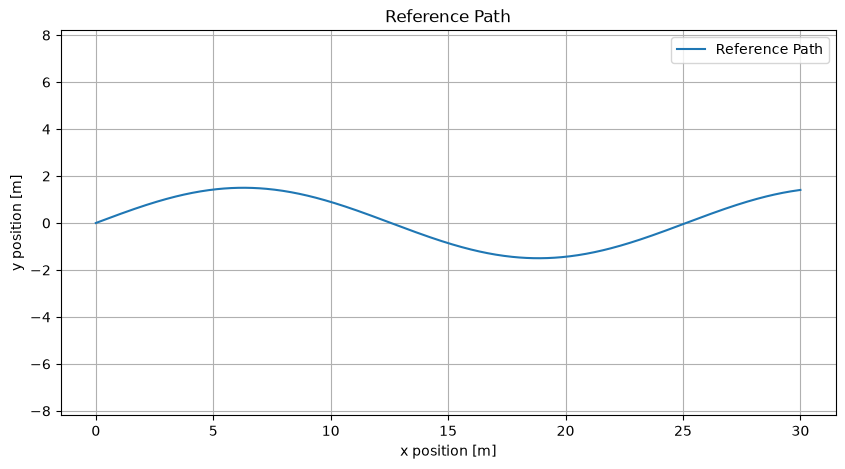

In [2]:
# 2-17D — Define the Reference Path

# Reference path
x_path = np.linspace(0.0, 30.0, 600)
y_path = 1.5 * np.sin(0.25 * x_path)

reference_path = np.column_stack((x_path, y_path))

print(f"Number of reference points: {len(reference_path)}")
print(f"Path start: ({reference_path[0, 0]:.2f}, {reference_path[0, 1]:.2f})")
print(f"Path end:   ({reference_path[-1, 0]:.2f}, {reference_path[-1, 1]:.2f})")

plt.figure(figsize=(10, 5))
plt.plot(x_path, y_path, label="Reference Path")
plt.xlabel("x position [m]")
plt.ylabel("y position [m]")
plt.title("Reference Path")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()

## Vehicle State and Parameters

The vehicle is represented using the kinematic bicycle model.

The state is defined as:

\[
[x,\ y,\ \theta,\ v]
\]

where \(x\) and \(y\) represent position, \(\theta\) represents vehicle heading, and \(v\) represents longitudinal velocity.

The wheelbase and simulation parameters are defined before connecting the vehicle model to the controller.

In [3]:
# 3-17D — Define Vehicle State and Parameters

# Vehicle parameters
wheelbase = 2.5          # m
velocity = 2.0           # m/s
dt = 0.05                # simulation time step
simulation_time = 15.0   # s

# Initial vehicle state
x0 = 0.0
y0 = -1.0
theta0 = 0.0

initial_state = np.array([x0, y0, theta0, velocity], dtype=float)

print("Vehicle parameters:")
print(f"Wheelbase:        {wheelbase:.2f} m")
print(f"Velocity:         {velocity:.2f} m/s")
print(f"Time step:        {dt:.2f} s")
print(f"Simulation time:  {simulation_time:.2f} s")

print("\nInitial state:")
print(f"x = {x0:.2f} m")
print(f"y = {y0:.2f} m")
print(f"theta = {theta0:.2f} rad")
print(f"v = {velocity:.2f} m/s")

Vehicle parameters:
Wheelbase:        2.50 m
Velocity:         2.00 m/s
Time step:        0.05 s
Simulation time:  15.00 s

Initial state:
x = 0.00 m
y = -1.00 m
theta = 0.00 rad
v = 2.00 m/s


## Pure Pursuit Controller

Pure Pursuit determines a steering command from a target point located ahead of the vehicle.

The angle between the vehicle heading and the line connecting the vehicle to the target point is denoted by \(\alpha\).

The desired path curvature is calculated as:

\[
\kappa = \frac{2\sin(\alpha)}{L_d}
\]

where \(L_d\) is the lookahead distance.

The curvature is then converted into a steering angle using the bicycle model:

\[
\delta = \tan^{-1}(L\kappa)
\]

where \(L\) is the vehicle wheelbase.

In [15]:
# 4-17D — Define the Pure Pursuit Controller

def pure_pursuit_steering(
    x,
    y,
    theta,
    wheelbase,
    reference_path,
    lookahead_distance,
    max_steering_angle=np.deg2rad(30)
):
    """
    Calculate the Pure Pursuit steering command.

    Parameters:
        x, y                 : vehicle position
        theta                : vehicle heading [rad]
        wheelbase            : vehicle wheelbase [m]
        reference_path       : Nx2 reference path
        lookahead_distance   : lookahead distance [m]
        max_steering_angle   : steering saturation [rad]

    Returns:
        steering_angle       : commanded steering angle [rad]
        target_point         : selected lookahead point
        target_index         : index of lookahead point
    """

    # Calculate distance from vehicle to every reference point
    distances = np.sqrt(
        (reference_path[:, 0] - x) ** 2 +
        (reference_path[:, 1] - y) ** 2
    )

    # Find the closest point on the reference path
    nearest_index = np.argmin(distances)

    # Search forward from the nearest point
    forward_indices = np.arange(
        nearest_index,
        len(reference_path)
    )

    forward_distances = distances[forward_indices]

    # Find the first forward point at or beyond the lookahead distance
    lookahead_indices = forward_indices[
        forward_distances >= lookahead_distance
    ]

    if len(lookahead_indices) == 0:
        target_index = len(reference_path) - 1
    else:
        target_index = lookahead_indices[0]

    target_x = reference_path[target_index, 0]
    target_y = reference_path[target_index, 1]

    # Angle from vehicle to target point
    target_angle = np.arctan2(
        target_y - y,
        target_x - x
    )

    # Heading error to target point
    alpha = target_angle - theta

    # Normalize angle to [-pi, pi]
    alpha = np.arctan2(
        np.sin(alpha),
        np.cos(alpha)
    )

    # Pure Pursuit curvature
    curvature = (
        2.0 * np.sin(alpha) / lookahead_distance
    )

    # Convert curvature to steering angle
    steering_angle = np.arctan(
        wheelbase * curvature
    )

    # Steering saturation
    steering_angle = np.clip(
        steering_angle,
        -max_steering_angle,
        max_steering_angle
    )

    target_point = np.array([
        target_x,
        target_y
    ])

    return steering_angle, target_point, target_index


print("Pure Pursuit controller defined successfully.")

Pure Pursuit controller defined successfully.


## Lookahead Target Selection

The lookahead target is the reference-path point used by the controller to determine the steering command.

Before running a complete vehicle simulation, the target-selection mechanism is tested independently to verify that the controller can identify a suitable point ahead of the vehicle.

Pure Pursuit target selection:
Vehicle position: (2.00, -0.50)
Lookahead distance: 2.00 m
Target index: 65
Target point: (3.26, 1.09)
Steering command: 30.00 deg


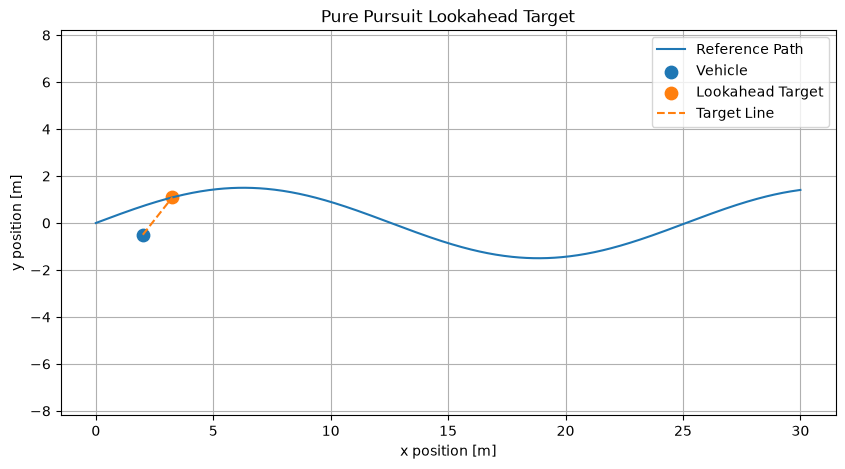

In [16]:
# 5-17D — Calculate the Lookahead Target

test_x = 2.0
test_y = -0.5
test_theta = 0.0

lookahead_distance = 2.0

steering_test, target_point, target_index = pure_pursuit_steering(
    test_x,
    test_y,
    test_theta,
    wheelbase,
    reference_path,
    lookahead_distance
)

print("Pure Pursuit target selection:")
print(f"Vehicle position: ({test_x:.2f}, {test_y:.2f})")
print(f"Lookahead distance: {lookahead_distance:.2f} m")
print(f"Target index: {target_index}")
print(
    f"Target point: "
    f"({target_point[0]:.2f}, {target_point[1]:.2f})"
)
print(f"Steering command: {np.rad2deg(steering_test):.2f} deg")

plt.figure(figsize=(10, 5))
plt.plot(
    reference_path[:, 0],
    reference_path[:, 1],
    label="Reference Path"
)
plt.scatter(
    test_x,
    test_y,
    s=80,
    label="Vehicle"
)
plt.scatter(
    target_point[0],
    target_point[1],
    s=80,
    label="Lookahead Target"
)
plt.plot(
    [test_x, target_point[0]],
    [test_y, target_point[1]],
    "--",
    label="Target Line"
)

plt.xlabel("x position [m]")
plt.ylabel("y position [m]")
plt.title("Pure Pursuit Lookahead Target")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()

## Steering Command Response

The steering command depends on the relative position and heading of the vehicle with respect to the selected lookahead target.

Several vehicle positions are tested to observe how Pure Pursuit responds to different geometric situations.

In [17]:
# 6-17D — Calculate the Steering Command

test_positions = [
    (-1.0, -0.5),
    (2.0, -0.5),
    (5.0, 0.0),
    (8.0, 1.0)
]

print("Pure Pursuit steering responses:")
print("--------------------------------")

for test_x, test_y in test_positions:

    steering, target, index = pure_pursuit_steering(
        test_x,
        test_y,
        0.0,
        wheelbase,
        reference_path,
        lookahead_distance
    )

    print(
        f"Vehicle ({test_x:5.2f}, {test_y:5.2f}) -> "
        f"Target ({target[0]:5.2f}, {target[1]:5.2f}) -> "
        f"Steering {np.rad2deg(steering):6.2f} deg"
    )

Pure Pursuit steering responses:
--------------------------------
Vehicle (-1.00, -0.50) -> Target ( 0.85,  0.32) -> Steering  30.00 deg
Vehicle ( 2.00, -0.50) -> Target ( 3.26,  1.09) -> Steering  30.00 deg
Vehicle ( 5.00,  0.00) -> Target ( 6.36,  1.50) -> Steering  30.00 deg
Vehicle ( 8.00,  1.00) -> Target (10.02,  0.89) -> Steering  -7.57 deg


## Single-State Controller Test

A single vehicle state is used to perform a basic sanity check of the complete Pure Pursuit calculation.

The test verifies that a valid target point and steering command are produced before the controller is integrated into the vehicle simulation.

In [18]:
# 7-17D — Test Pure Pursuit on a Single Vehicle State

single_test_state = np.array([
    3.0,    # x
    -0.8,   # y
    0.0,    # heading
    velocity
])

steering_angle, target_point, target_index = pure_pursuit_steering(
    single_test_state[0],
    single_test_state[1],
    single_test_state[2],
    wheelbase,
    reference_path,
    lookahead_distance
)

print("Single-state Pure Pursuit test")
print("--------------------------------")
print(f"Vehicle x: {single_test_state[0]:.2f} m")
print(f"Vehicle y: {single_test_state[1]:.2f} m")
print(f"Vehicle heading: {single_test_state[2]:.2f} rad")
print(f"Target index: {target_index}")
print(
    f"Target point: "
    f"({target_point[0]:.2f}, {target_point[1]:.2f})"
)
print(f"Steering angle: {np.rad2deg(steering_angle):.2f} deg")

Single-state Pure Pursuit test
--------------------------------
Vehicle x: 3.00 m
Vehicle y: -0.80 m
Vehicle heading: 0.00 rad
Target index: 70
Target point: (3.51, 1.15)
Steering angle: 30.00 deg


## Vehicle Simulation with Pure Pursuit

The Pure Pursuit controller is now connected to the kinematic bicycle model.

At each simulation step, the controller:

1. Finds the lookahead target.
2. Calculates the steering command.
3. Propagates the vehicle state using the kinematic bicycle model.
4. Stores the resulting vehicle trajectory and steering command.

In [19]:
# 8-17D — Simulate Vehicle Motion

def simulate_pure_pursuit(
    reference_path,
    wheelbase,
    velocity,
    initial_state,
    lookahead_distance,
    dt,
    simulation_time
):
    """
    Simulate a vehicle controlled by Pure Pursuit.
    """

    steps = int(simulation_time / dt)

    states = np.zeros((steps, 4))
    steering_history = np.zeros(steps)
    target_history = np.zeros((steps, 2))
    target_indices = np.zeros(steps, dtype=int)

    state = initial_state.copy()

    for i in range(steps):

        x, y, theta, v = state

        steering, target_point, target_index = pure_pursuit_steering(
            x,
            y,
            theta,
            wheelbase,
            reference_path,
            lookahead_distance
        )

        # Kinematic bicycle model
        x_dot = v * np.cos(theta)
        y_dot = v * np.sin(theta)
        theta_dot = (v / wheelbase) * np.tan(steering)

        # Euler integration
        state = state + dt * np.array([
            x_dot,
            y_dot,
            theta_dot,
            0.0
        ])

        states[i] = state
        steering_history[i] = steering
        target_history[i] = target_point
        target_indices[i] = target_index

    return states, steering_history, target_history, target_indices


states, steering_history, target_history, target_indices = (
    simulate_pure_pursuit(
        reference_path=reference_path,
        wheelbase=wheelbase,
        velocity=velocity,
        initial_state=initial_state,
        lookahead_distance=lookahead_distance,
        dt=dt,
        simulation_time=simulation_time
    )
)

print("Simulation completed.")
print(f"Number of simulation steps: {len(states)}")
print(
    f"Final vehicle position: "
    f"({states[-1, 0]:.2f}, {states[-1, 1]:.2f})"
)
print(f"Final vehicle heading: {np.rad2deg(states[-1, 2]):.2f} deg")

Simulation completed.
Number of simulation steps: 300
Final vehicle position: (28.53, 1.11)
Final vehicle heading: 14.15 deg


## Tracked Path

The simulated vehicle trajectory is compared with the reference path.

This provides a visual assessment of how effectively the Pure Pursuit controller guides the vehicle along the desired trajectory.

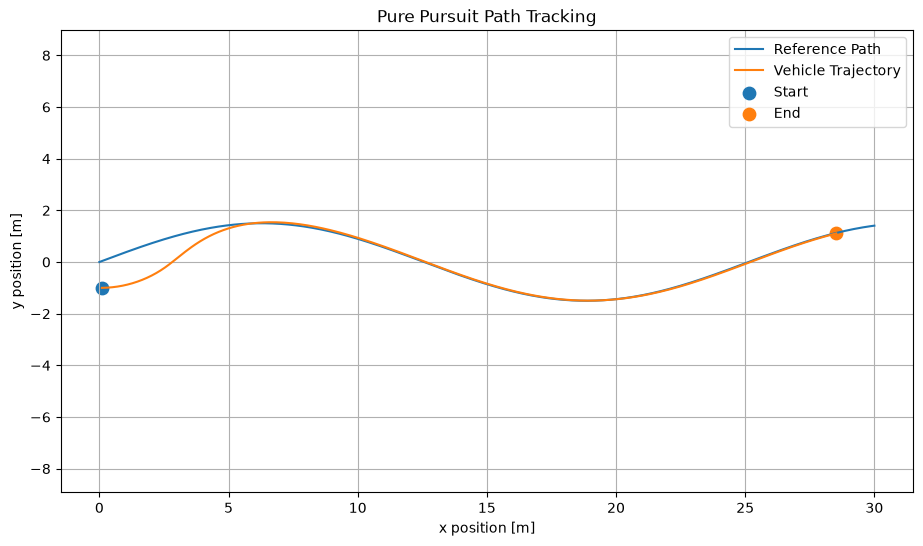

In [20]:
# 9-17D — Visualize the Tracked Path

plt.figure(figsize=(11, 6))

plt.plot(
    reference_path[:, 0],
    reference_path[:, 1],
    label="Reference Path"
)

plt.plot(
    states[:, 0],
    states[:, 1],
    label="Vehicle Trajectory"
)

plt.scatter(
    states[0, 0],
    states[0, 1],
    s=80,
    label="Start"
)

plt.scatter(
    states[-1, 0],
    states[-1, 1],
    s=80,
    label="End"
)

plt.xlabel("x position [m]")
plt.ylabel("y position [m]")
plt.title("Pure Pursuit Path Tracking")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()

## Tracking Error Evaluation

The tracking error is defined as the minimum Euclidean distance between the vehicle position and the reference path.

The mean, maximum, and final tracking errors are calculated to provide quantitative measures of tracking performance.

Tracking error evaluation
-------------------------
Mean tracking error:    0.1789 m
Maximum tracking error: 1.2244 m
Final tracking error:   0.0306 m


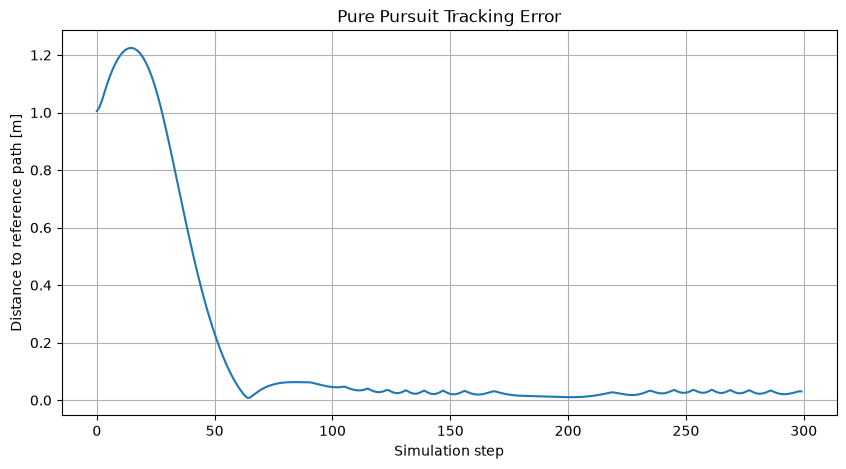

In [21]:
# 10-17D — Evaluate Tracking Error

def calculate_tracking_error(states, reference_path):
    """
    Calculate the minimum Euclidean distance from each
    vehicle position to the reference path.
    """

    vehicle_positions = states[:, :2]

    errors = []

    for position in vehicle_positions:

        distances = np.sqrt(
            (reference_path[:, 0] - position[0]) ** 2 +
            (reference_path[:, 1] - position[1]) ** 2
        )

        errors.append(np.min(distances))

    return np.array(errors)


tracking_error = calculate_tracking_error(
    states,
    reference_path
)

mean_tracking_error = np.mean(tracking_error)
max_tracking_error = np.max(tracking_error)
final_tracking_error = tracking_error[-1]

print("Tracking error evaluation")
print("-------------------------")
print(f"Mean tracking error:    {mean_tracking_error:.4f} m")
print(f"Maximum tracking error: {max_tracking_error:.4f} m")
print(f"Final tracking error:   {final_tracking_error:.4f} m")

plt.figure(figsize=(10, 5))
plt.plot(tracking_error)
plt.xlabel("Simulation step")
plt.ylabel("Distance to reference path [m]")
plt.title("Pure Pursuit Tracking Error")
plt.grid(True)
plt.show()

## Effect of Lookahead Distance

The lookahead distance is an important Pure Pursuit parameter.

A smaller lookahead distance causes the controller to respond to a target closer to the vehicle, while a larger lookahead distance makes the controller consider a point farther along the path.

Several lookahead distances are therefore compared using the same vehicle and reference-path conditions.

In [22]:
# 11-17D — Compare Lookahead Distances

lookahead_values = [1.0, 2.0, 3.0, 4.0]

comparison_results = {}

for ld in lookahead_values:

    test_states, test_steering, _, _ = simulate_pure_pursuit(
        reference_path=reference_path,
        wheelbase=wheelbase,
        velocity=velocity,
        initial_state=initial_state,
        lookahead_distance=ld,
        dt=dt,
        simulation_time=simulation_time
    )

    test_error = calculate_tracking_error(
        test_states,
        reference_path
    )

    comparison_results[ld] = {
        "states": test_states,
        "steering": test_steering,
        "error": test_error
    }

    print(
        f"Lookahead = {ld:.1f} m | "
        f"Mean error = {np.mean(test_error):.4f} m | "
        f"Max error = {np.max(test_error):.4f} m"
    )

Lookahead = 1.0 m | Mean error = 0.2388 m | Max error = 1.2244 m
Lookahead = 2.0 m | Mean error = 0.1789 m | Max error = 1.2244 m
Lookahead = 3.0 m | Mean error = 0.2407 m | Max error = 1.2244 m
Lookahead = 4.0 m | Mean error = 0.3484 m | Max error = 1.2477 m


## Steering Behaviour

The steering commands generated for the different lookahead distances are compared.

The resulting steering profiles help illustrate how the controller's responsiveness changes as the lookahead distance is varied.

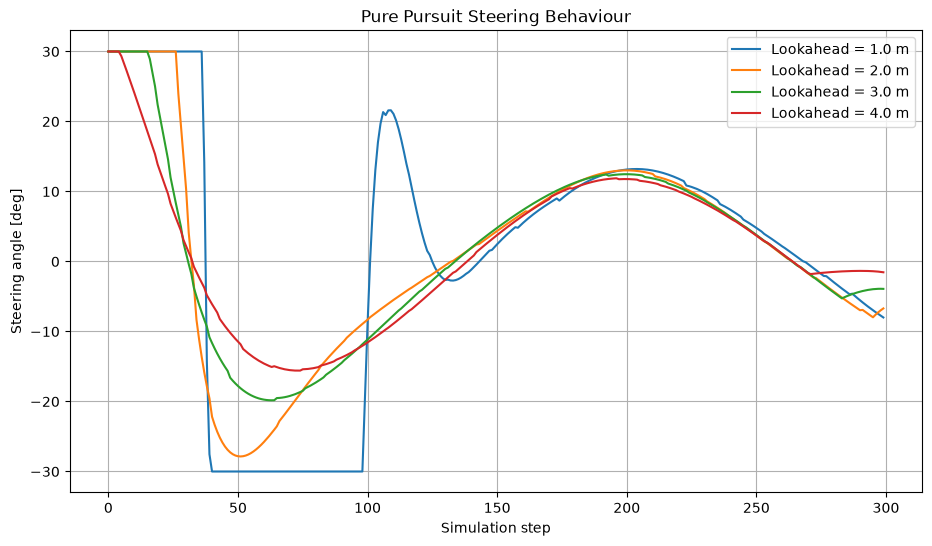

In [23]:
# 12-17D — Visualize Steering Behaviour

plt.figure(figsize=(11, 6))

for ld in lookahead_values:

    steering_deg = np.rad2deg(
        comparison_results[ld]["steering"]
    )

    plt.plot(
        steering_deg,
        label=f"Lookahead = {ld:.1f} m"
    )

plt.xlabel("Simulation step")
plt.ylabel("Steering angle [deg]")
plt.title("Pure Pursuit Steering Behaviour")
plt.grid(True)
plt.legend()
plt.show()

## Results Summary

The main tracking metrics are collected for each tested lookahead distance.

This comparison provides a quantitative basis for evaluating the influence of the lookahead parameter on Pure Pursuit performance.

In [24]:
# 13-17D — Summarize Pure Pursuit Results

print("Pure Pursuit Summary")
print("====================")

print(f"Vehicle wheelbase: {wheelbase:.2f} m")
print(f"Vehicle velocity:  {velocity:.2f} m/s")

print("\nLookahead comparison:")
print("--------------------")

for ld in lookahead_values:

    error = comparison_results[ld]["error"]

    print(
        f"{ld:.1f} m -> "
        f"Mean error: {np.mean(error):.4f} m, "
        f"Maximum error: {np.max(error):.4f} m, "
        f"Final error: {error[-1]:.4f} m"
    )

print("\nKey observation:")
print(
    "The lookahead distance influences the balance between "
    "path-following responsiveness and steering behaviour."
)

Pure Pursuit Summary
Vehicle wheelbase: 2.50 m
Vehicle velocity:  2.00 m/s

Lookahead comparison:
--------------------
1.0 m -> Mean error: 0.2388 m, Maximum error: 1.2244 m, Final error: 0.0157 m
2.0 m -> Mean error: 0.1789 m, Maximum error: 1.2244 m, Final error: 0.0306 m
3.0 m -> Mean error: 0.2407 m, Maximum error: 1.2244 m, Final error: 0.0592 m
4.0 m -> Mean error: 0.3484 m, Maximum error: 1.2477 m, Final error: 0.1118 m

Key observation:
The lookahead distance influences the balance between path-following responsiveness and steering behaviour.


## Final Validation

The final checks verify that the reference path, vehicle states, steering commands, and tracking-error calculations contain valid numerical values.

The steering command is also checked against the defined steering-angle limit.

In [25]:
# 14-17D — Final Validation

assert reference_path.shape[1] == 2
assert states.shape[1] == 4
assert len(steering_history) == len(states)

assert np.all(np.isfinite(states))
assert np.all(np.isfinite(steering_history))
assert np.all(np.isfinite(tracking_error))

assert np.all(
    np.abs(steering_history) <= np.deg2rad(30) + 1e-9
)

assert mean_tracking_error >= 0.0
assert max_tracking_error >= 0.0
assert final_tracking_error >= 0.0

print("Final validation passed.")
print("Reference path: valid")
print("Vehicle states: valid")
print("Steering commands: valid and within limits")
print("Tracking errors: valid")
print("Pure Pursuit simulation: completed successfully")

Final validation passed.
Reference path: valid
Vehicle states: valid
Steering commands: valid and within limits
Tracking errors: valid
Pure Pursuit simulation: completed successfully
